# 02 &nbsp;What do we decide before looking?

**The problem.** Once results are on the screen, it is very easy to move the goalposts: switch to whichever metric won, lower the bar a little, or call a flat result "directionally positive". Every one of those moves feels reasonable in the moment, and together they make a test say whatever we hoped.

**The approach.** Write the decision down first, as a file the analysis has to read: what we are deciding, which metric decides it, what it is worth, and the rule for acting. Every later notebook loads [`plans/hillstrom_email.yaml`](../plans/hillstrom_email.yaml), so the rule can't quietly change after the results are in.

> In a live test this file is written before launch. Here it was written after the trust checks in notebook 01 and before the formal readout, and none of its thresholds were tuned to the results.

In [1]:
from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.spec import load_spec

style.use_style()
spec = load_spec("hillstrom_email.yaml")
spec.summary()

,Decided up front
,
Question,Should customers like these get the men's emai...
Decision owner,Email marketing lead
Options,"No email, Men's email, Women's email"
Primary metric,"Revenue per customer, two weeks after the send"
Secondary metrics,"Visited the site, Bought something"
Guardrails,Unsubscribe rate (not measured)
Gross margin,35%
Cost per email,$0.02
Minimum worthwhile profit,"$20 per 1,000 emails"


## 1. Can the data answer the plan?

Before anything else, check that every option, metric and covariate the plan names actually exists in the data. A plan that refers to a column we don't have is a plan we can't keep.

In [2]:
df = load_hillstrom()
problems = spec.validate_against(df)
print("The data can answer this plan." if not problems else "\n".join(problems))

The data can answer this plan.


## 2. Why revenue decides, and not visits

Visits are the easiest number to move and the least connected to the business. An email can lift visits a lot and still lose money. Revenue per customer ties directly to the decision, so it is the **one** primary metric.

Visits and purchases are still reported, but as **secondary** metrics that help explain *why* revenue moved. Two emails times two secondary metrics is four extra comparisons, so they get a Holm correction to keep false alarms in check. The primary metric gets none, because only one comparison per email decides anything.

## 3. What an email has to earn

Revenue is not profit. The plan turns revenue into profit with two assumptions: a **35% gross margin**, and a **cost of $0.02 per email** (sending, plus an allowance for list fatigue). It also sets the smallest profit worth acting on: **$20 per 1,000 emails**. Below that, the change isn't worth the effort and the risk.

Those three numbers draw the whole decision map, before any result goes on it.

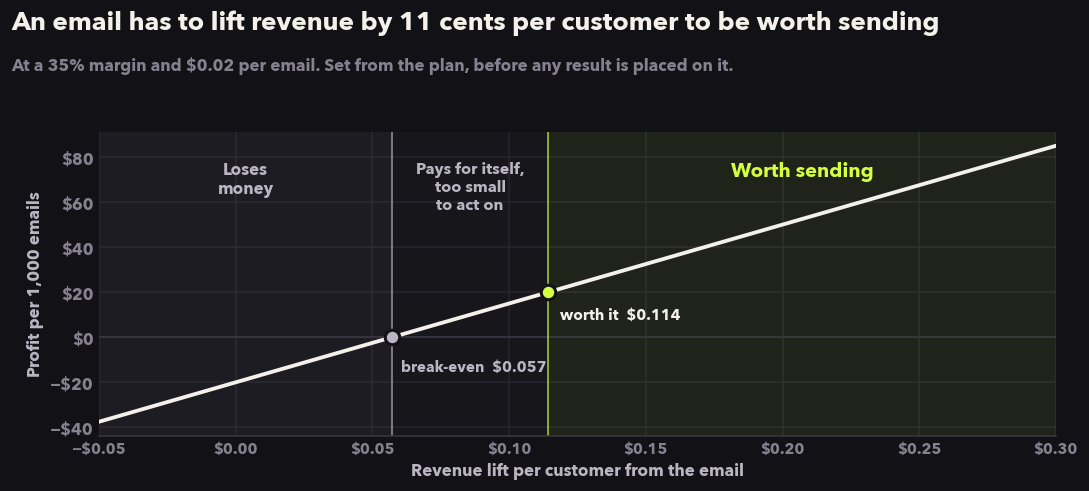

In [3]:
econ = spec.economics
fig, ax = plots.decision_zones_plot(econ)
style.headline(
    fig,
    f"An email has to lift revenue by {100 * econ.worthwhile_lift:.0f} cents per customer to be worth sending",
    f"At a {econ.gross_margin:.0%} margin and ${econ.cost_per_email:.2f} per email. "
    "Set from the plan, before any result is placed on it.",
)
style.save(fig, "decision_zones")

In [4]:
print(f"Break-even lift:  ${econ.break_even_lift:.3f} per customer")
print(f"Worthwhile lift:  ${econ.worthwhile_lift:.3f} per customer")

Break-even lift:  $0.057 per customer
Worthwhile lift:  $0.114 per customer


## 4. The rule for acting

Significance alone doesn't decide. The rule is about money and risk:

- **Choose** the option with the highest expected profit per 1,000 emails.
- **Ship it** only if it has at least an **80% chance of being the best** option, and choosing it would cost at most **$10 per 1,000 emails** in expected loss if it turns out not to be.
- **Otherwise** keep sending no email and extend the test.

*Expected loss* is the question a leader actually asks: "if we're wrong, how much does it cost us?" A tiny risk of a big loss and a big risk of a tiny loss can have the same p-value and very different answers.

## 5. What this plan can't cover

- **Unsubscribes aren't in the data.** In a live test, a rise in unsubscribes could block a send on its own, whatever revenue did. Here it is listed as a guardrail we can't check, so the final recommendation will carry that caveat.
- **Margin and email cost are assumptions.** A later module checks how sensitive the decision is to them. If a small change in margin flips the answer, that is worth knowing before acting.
- **Two weeks is short.** Effects on repeat purchases or long-term engagement are out of reach.

## Next

Before applying any method to this plan, check that the method itself works on this data. Notebook 03 runs thousands of fake A/A tests on real no-email customers to see how often each method raises a false alarm.